# NumPy Feedforward ANN Trained With Particle Swarm Optimization

A fully connected, configurable classifier for UCI Banknote Authentication. **NumPy is the only third-party dependency**; Python's standard library handles paths, timing, hashes and persistence. No pretrained parameters, autodifferentiation, backpropagation, scikit-learn, TensorFlow, PyTorch or PySwarms are used. Run code cells in order with NumPy installed in the selected kernel. The full default search took approximately 76 seconds in the development environment; runtime varies by hardware and NumPy build.

## Research and Sources

Sources inspected online on **2026-11-02**. This is a focused review of accessible implementations, not an exhaustive literature review or a state-of-the-art leaderboard. Reported results are authors' claims, not independently reproduced benchmarks.

| Source | Architecture / method | Evidence and limitations |
| --- | --- | --- |
| [UCI Banknote Authentication](https://archive.ics.uci.edu/dataset/267/banknote+authentication), Volker Lohweg; [dataset DOI](https://doi.org/10.24432/C55P57) | 1,372 rows; four wavelet-derived features; binary target; no missing values. | Authoritative dataset description. Features: variance, skewness, curtosis and entropy. Dataset license: CC BY 4.0. Preserve numeric labels because the UCI variables table does not explicitly define which number means genuine. |
| [Shan Swanlow: Detecting Forged Bank Notes](https://shans96.github.io/portfolio/banknote-authentication/); [linked source repository](https://github.com/shans96/banknote-authentication) | Vectorized NumPy `4 -> 10 -> 1`, ReLU/sigmoid, cross-entropy, gradient descent; later He initialization. | Describes shuffled 60/20/20 train/validation/test data. Reports approximately 99.39% training and 98.9% validation initially, then 100% across all three sets after changing initialization. Closest implementation reference to the requested constraints. The article's code was inspected; its linked repository was not independently reproduced. |
| [GeeksforGeeks: Securing Transactions: Banknote Classification with Neural Networks](https://www.geeksforgeeks.org/deep-learning/securing-transactions-banknote-classification-with-neural-networks/) (updated July 23, 2025) | TensorFlow/Keras `4 -> 8 -> 1`, ReLU/sigmoid, Adam, binary cross-entropy, 20 epochs. | Uses a 60/40 random split. Supports starting with a compact model, but is not NumPy-only or PSO. Its loader reverses numeric labels; this notebook does not. No comparable numerical accuracy is quoted because the displayed output is an image. |
| [Diellza Raci: banknote-classification-ml](https://github.com/diellzaracci/banknote-classification-ml) | Scikit-learn `MLPClassifier`; hidden widths `(10,)`, `(20, 10)`, `(30, 20, 10)`. | README reports 95.8%, 96.1%, 98.3% respectively, plus experiments varying train/test ratios. Useful architecture comparisons, not a controlled benchmark against these other sources. Changing the split to obtain the best test score is not adopted here. |
| [PySwarms: Training a Neural Network](https://pyswarms.readthedocs.io/en/latest/examples/usecases/train_neural_network.html) | **Iris, not banknote**: `4 -> 20 -> 3`, tanh/softmax. Flattens every weight and bias into a particle; minimizes negative log-likelihood with global-best PSO. | Method reference only. Adapt the parameter-vector idea to arbitrary layer sizes and implement PSO directly with NumPy. Its Iris accuracy is not a banknote benchmark. |

### Selected Starting Point

**Swanlow is the best fit to this specification**, because it demonstrates NumPy matrix-based classification on the same dataset and documents a separate test split. Its reported perfect score does not prove universal superiority. The implementation below is original code based on the mathematical design, not copied source: generalize the shallow ReLU/sigmoid network, replace gradient training entirely with PSO, stabilize probability/loss calculations, add fold-local standardization, and tune topology plus optimizer settings. The smaller Keras implementation supports starting compact. Every additional weight or bias increases PSO's search dimension, with no established benefit from a large network for just four inputs.

## Model and Objective

For each non-input layer, $A_{\ell}=\phi_{\ell}(A_{\ell-1}W_{\ell}+b_{\ell})$. `FeedForwardANN(layer_sizes, activations)` takes every width including input/output and one activation per non-input layer. The input is the feature matrix and has no separate activation. Example: `(4, 8, 4, 1)` with `('relu', 'tanh', 'logistic')`. Arbitrary positive widths and depth are supported. For this binary task, four features determine the input width and **one logistic output** represents $P(y=1)$. Other output activations are available through the general forward-pass API but are rejected by the binary probability/loss interface.

- Logistic: $\sigma(z)=1/(1+e^{-z})$, implemented stably using `logaddexp`; `sigmoid` is an alias.
- ReLU: $\max(0,z)$.
- Hyperbolic tangent: $\tanh(z)$.
- Optional linear activation: $\phi(z)=z$.
- A particle contains each layer's flattened weights followed by biases in deterministic order. Total dimension: $D=\sum_{\ell=1}^{L}(n_{\ell-1}+1)n_{\ell}$.
- Training minimizes mean BCE from logits, $\operatorname{mean}(\log(1+e^z)-yz)$, plus `l2 * mean(weights**2)`. Biases are not penalized; validation BCE excludes regularization.
- ReLU weights start from He-uniform-style bounds; other layers use Xavier-uniform-style bounds. Biases receive small independent Gaussian values for swarm diversity. All learned parameters start randomly.

PSO updates $V \leftarrow wV+c_1R_1(P-X)+c_2R_2(G-X)$ and $X \leftarrow X+V$. Random coefficients are independent per particle and dimension. Inertia decreases linearly, velocities are clamped, parameters stay inside symmetric bounds, and velocity is zeroed on coordinates clipped at a boundary. Personal/global best positions are independent copies. There are no derivatives. Initial coefficients near 1.49618 and 0.7298 are conventional starting values, not proof of optimality or an exact constriction-PSO implementation. References: [Kennedy and Eberhart (1995), Particle Swarm Optimization](https://doi.org/10.1109/ICNN.1995.488968), and the inspected PySwarms ANN encoding example above.

## Experiment Protocol

1. Load the local headerless CSV; verify shape, finite values and target encoding; record SHA256. Reject identical feature vectors with conflicting labels. Remove **24 exact duplicate rows** before splitting, retaining original row indices: 1,348 unique observations remain. Near duplicates are retained; specimen identities are unavailable, so this is not specimen-grouped evaluation.
2. Reserve a stratified 20% locked test set (270 rows; split seed 2026). All search uses only the other 1,078 observations. Never change the split or threshold to improve test results.
3. Three fixed stratified development folds (seed 31415), each with two independent PSO seeds (11, 29). A scaler is fitted only on each fold's training rows. Seeds vary initialization and PSO randomness; folds do not change between seeds. Each training run uses the full fold training set as its deterministic objective.
4. Screen widths `(4,)`, `(8,)`, `(12,)`, `(8, 4)` with homogeneous tanh/ReLU/logistic hidden activations, plus two mixed two-hidden-layer configurations. All have one logistic output. Fourteen candidates use 32 particles and 180 iterations each. Widths bracket the cited compact 8/10-node networks rather than copying one fixed topology.
5. Refine the three leading architectures with three explicit PSO profiles, each using 48 particles and 350 iterations. Profiles vary attraction coefficients, inertia, bounds, velocity fraction and L2. This staged search is **not exhaustive**; it can miss interactions and discard an architecture that would improve with another budget. Edit `ARCHITECTURES`, `BASE_PSO`, `REFINEMENT_PSO`, `SEARCH_SEEDS` and the folds to expand it. Output activation and classification threshold are fixed for the task.
6. Select across all 23 evaluated configurations by mean fold/seed accuracy, then lower unregularized validation BCE, then fewer parameters. There are **138 CV fits and 1,396,320 particle objective evaluations**, excluding smoke checks and final refits. Runs have equal particle/iteration budgets within each stage, not across stages. Reported fold/seed SD is descriptive, not a confidence interval. Selection repeatedly uses these folds, so the selected validation score is optimistic; the locked test is the external check, not nested CV.
7. Refit the chosen configuration on the full development set with seeds 101, 202, 303; select a restart **only by its regularized development training objective**. Fit scaling on development data only. Evaluate the locked test once at the prespecified 0.5 threshold. Export configuration, fold scores, split indices, scaling, parameters, training history, predictions and environment versions.

## Executed Result

The executed search selected **`4 -> 12 -> 1`, ReLU/logistic**, 73 trainable parameters: 48 particles, 350 iterations, `c1=1.7`, `c2=1.3`, inertia `0.9 -> 0.4`, bounds `[-8, 8]`, velocity fraction `0.15`, L2 `1e-5`. It obtained 100% mean validation accuracy; several candidates tied on accuracy and BCE broke the tie. Final restart: seed 202. On 270 held-out unique rows it obtained **270/270 correct**, confusion matrix `[[148, 0], [0, 122]]`, F1 and ROC AUC of 1.0, versus a 54.81% majority baseline. These figures describe this saved run; rerunning with edited settings requires reading new outputs and updating this paragraph.

The 95% Wilson accuracy interval is approximately **98.60% to 100%**, conditional on treating held-out rows as independent. It does not account for unknown specimen dependence, the small dataset, distribution shift or future tuning. Perfect classification here does not establish real-world fraud detection reliability. No claim is made to beat cited implementations: they use different splits, duplicate policies, training algorithms and evaluation protocols. **Best means best among the candidates and seeds evaluated here**, not a mathematical global optimum.

The code cells below contain executed numerical checks for activations, parameter layout, batched/deep forward passes, loss, PSO convergence/state, splits/scaling, the tuning pipeline, metrics, persistence and inference. Artifacts are stored beside this notebook in `ann_results/`. `predict_banknotes` accepts raw features in the recorded feature order and returns numeric classes plus class-1 probabilities; it applies saved scaling automatically.

In [1]:
# Dataset source: Lohweg, UCI Banknote Authentication, https://doi.org/10.24432/C55P57
# Closest NumPy implementation: https://shans96.github.io/portfolio/banknote-authentication/
# Supporting compact ANN: https://www.geeksforgeeks.org/deep-learning/securing-transactions-banknote-classification-with-neural-networks/
# Larger MLP experiments: https://github.com/diellzaracci/banknote-classification-ml
# PSO parameter-vector method (Iris, not banknote): https://pyswarms.readthedocs.io/en/latest/examples/usecases/train_neural_network.html
# PSO origin: Kennedy and Eberhart (1995), https://doi.org/10.1109/ICNN.1995.488968
# These are conceptual references; this notebook uses original NumPy code and PSO-only training.
# Full source comparison, adaptation rationale and evaluation limitations appear above.

## ANN Architecture and Training Classes

The implementation separates network definition, objective, optimization, and orchestration:

- `FeedForwardANN` defines layer widths and activations, maps flat PSO vectors to layer parameters, performs batched forward passes, and initializes candidate swarms.
- `BinaryCrossEntropyObjective` binds the ANN to one training partition and returns one regularized loss per particle.
- `ParticleSwarmOptimizer` owns particle positions, velocities, personal/global bests, and optimization history.
- `ANNTrainer` composes the network, objective, and optimizer into one reproducible fit operation.

For this dataset, each candidate uses four input nodes and one logistic output node. Hidden widths and activations are configured in `ARCHITECTURES`.

The local CSV currently contains one target written as `0` followed by a stray section sign. The loader reports and strips that exact suffix **in memory only**; the source data file is left unchanged. Other nonnumeric values still raise an error.

In [2]:
import numpy as np


def logistic(values):
    values = np.asarray(values, dtype=float)
    return np.exp(-np.logaddexp(0.0, -values))


ACTIVATIONS = {
    'logistic': logistic,
    'sigmoid': lambda values: 1 / (1 + np.exp(-values)),
    'relu': lambda values: np.maximum(0.0, values),
    'tanh': np.tanh,
    'linear': lambda values: values,
}


class FeedForwardANN:
    """Dense feedforward architecture; PSO candidates hold its trainable parameters."""

    def __init__(self, layer_sizes, activations):
        self.layer_sizes = tuple(layer_sizes)
        self.activations = tuple(activations)
        if len(self.layer_sizes) < 2 or any(
            not isinstance(width, (int, np.integer)) or width < 1
            for width in self.layer_sizes
        ):
            raise ValueError('Provide at least two positive integer layer sizes.')
        if len(self.activations) != len(self.layer_sizes) - 1:
            raise ValueError('Provide one activation per non-input layer.')
        if any(name not in ACTIVATIONS for name in self.activations):
            raise ValueError(f'Available activations: {tuple(ACTIVATIONS)}')

        # Keep a deterministic flat-vector layout so every PSO position maps to one ANN.
        # Vector self.layout looks like [(weight_start, weight_end, bias_end, fan_in, fan_out), ...]
        self.layout = []
        offset = 0
        for fan_in, fan_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:]):
            weight_end = offset + fan_in * fan_out # End index of the weight matrix for this layer in the flat vector
            bias_end = weight_end + fan_out # End index of the bias vector for this layer in the flat vector
            self.layout.append((offset, weight_end, bias_end, fan_in, fan_out))
            offset = bias_end # Update offset to the end of the bias vector for the next layer
        self.n_parameters = offset
        self.weight_indices = np.concatenate([
            np.arange(start, weight_end)
            for start, weight_end, _, _, _ in self.layout
        ])

    def unpack(self, particles):
        """View flat particle vectors as per-layer weight and bias tensors."""
        particles = np.asarray(particles, dtype=float)
        particles = np.atleast_2d(particles)
        if particles.ndim != 2 or particles.shape[1] != self.n_parameters:
            raise ValueError(f'Expected particles with {self.n_parameters} parameters.')
        
        # Iterate over each layer's layout to extract weights and biases from the flat particle vector
        for start, weight_end, bias_end, fan_in, fan_out in self.layout:
            yield (
                particles[:, start:weight_end].reshape(-1, fan_in, fan_out),
                particles[:, weight_end:bias_end, None].transpose(0, 2, 1),
            )

    def forward(self, features, particles, return_logits=False):
        """Evaluate one or many particle-defined networks on a feature matrix."""
        features = np.asarray(features, dtype=float)
        if features.ndim != 2 or features.shape[1] != self.layer_sizes[0]:
            raise ValueError('Features must have shape (samples, input_nodes).')

        # Broadcast samples across particles; only the final layer can return logits for BCE.
        outputs = features[None, :, :]
        for layer_index, ((weights, biases), name) in enumerate(
            zip(self.unpack(particles), self.activations)
        ):
            logits = outputs @ weights + biases
            if return_logits and layer_index == len(self.activations) - 1:
                return logits
            outputs = ACTIVATIONS[name](logits)
        return outputs

    def predict_proba(self, features, parameters):
        """Return class-1 probabilities for a single trained binary classifier."""
        if self.layer_sizes[-1] != 1 or self.activations[-1] not in ('sigmoid', 'logistic'):
            raise ValueError('Binary probabilities require one logistic output node.')
        return self.forward(features, parameters)[0, :, 0]

    def initialize(self, n_particles, rng):
        """Create a fresh swarm using activation-aware random weight scales."""
        particles = np.empty((n_particles, self.n_parameters))
        for (start, weight_end, bias_end, fan_in, fan_out), name in zip(
            self.layout, self.activations
        ):
            limit = np.sqrt(6.0 / (fan_in if name == 'relu' else fan_in + fan_out))
            particles[:, start:weight_end] = rng.uniform(
                -limit, limit, (n_particles, fan_in * fan_out)
            )
            particles[:, weight_end:bias_end] = rng.normal(0.0, 0.1, (n_particles, fan_out))
        return particles


def binary_losses(network, features, labels, particles, l2=0.0):
    """Compute each particle's mean logit-based BCE plus weight-only L2 penalty."""
    if network.layer_sizes[-1] != 1 or network.activations[-1] not in ('logistic', 'sigmoid'):
        raise ValueError('Binary cross entropy requires one logistic output node.')
    labels = np.asarray(labels)
    if labels.shape != (len(features),) or not np.isin(labels, [0, 1]).all():
        raise ValueError('Labels must be a one-dimensional array of zeros and ones.')
    if l2 < 0:
        raise ValueError('L2 must be nonnegative.')

    # The logits form avoids taking log of rounded probabilities near 0 or 1.
    logits = network.forward(features, particles, return_logits=True)[:, :, 0]
    losses = np.mean(np.logaddexp(0.0, logits) - labels[None, :] * logits, axis=1)
    weights = np.atleast_2d(particles)[:, network.weight_indices]
    return losses + l2 * np.mean(weights ** 2, axis=1)

# Run basic checks for activations, parameter layout, batched forward pass, depth, and BCE.
with np.errstate(over='raise', invalid='raise'):
    np.testing.assert_allclose(logistic([-1000, 0, 1000]), [0, 0.5, 1])
    np.testing.assert_allclose(ACTIVATIONS['relu'](np.array([-2, 0, 2])), [0, 0, 2])
    np.testing.assert_allclose(ACTIVATIONS['tanh'](np.array([-2, 0, 2])), np.tanh([-2, 0, 2]))
    probe = FeedForwardANN((2, 2, 1), ('relu', 'logistic'))
    probe_parameters = np.array([1, 0, 0, 1, 0, 0, 1, -1, 0])
    np.testing.assert_allclose(probe.predict_proba([[2, 1]], probe_parameters), logistic([1]))
    np.testing.assert_allclose(
        probe.forward([[2, 1]], np.stack([probe_parameters] * 3))[:, 0, 0],
        np.repeat(logistic([1]), 3),
    )
    zero_parameters = np.zeros(probe.n_parameters)
    np.testing.assert_allclose(binary_losses(probe, [[2, 1]], [1], zero_parameters), np.log(2))
    deep_probe = FeedForwardANN((4, 5, 3, 1), ('tanh', 'relu', 'logistic'))
    assert deep_probe.forward(np.zeros((7, 4)), np.zeros((2, deep_probe.n_parameters))).shape == (2, 7, 1)
    
print('ANN checks passed: activations, parameter layout, batched forward pass, depth and BCE.')

ANN checks passed: activations, parameter layout, batched forward pass, depth and BCE.


## PSO Optimisation

**Particle swarm optimisation (PSO)** is a population-based, derivative-free search algorithm. Each particle in this notebook represents one complete ANN: its position vector contains every weight and bias. Its velocity is a proposed change to those parameters, not a gradient. A forward pass evaluates how well that candidate network classifies the training rows.

### What Each Particle Remembers

- **Current position** $X_i$: the candidate network's parameters.
- **Velocity** $V_i$: how those parameters move at the next iteration.
- **Personal best** $P_i$: the lowest-loss position that particle has visited.
- **Global best** $G$: the lowest-loss position any particle has visited.

At each iteration, independent random arrays $R_1$ and $R_2$ are drawn for each particle and parameter. Updates are synchronous: all particles move using the previously recorded global best, then their new positions are evaluated.

$$V_i^{t+1}=w_tV_i^t+c_1R_1\odot(P_i-X_i^t)+c_2R_2\odot(G-X_i^t)$$
$$X_i^{t+1}=X_i^t+V_i^{t+1}$$

The **inertia** term $w_tV_i^t$ maintains motion, the **cognitive** term pulls towards that particle's own best network, and the **social** term pulls towards the swarm's best network. Here, inertia decreases linearly to reduce momentum later in the search; this encourages refinement but does not guarantee convergence. Velocity clamping limits step sizes, parameter bounds keep weights and biases within the chosen search region, and a clipped coordinate has its velocity reset to zero.

### How Loss Guides the Swarm

For one row with true class $y$ and predicted class-1 probability $p$:

$$\ell(y,p)=-y\log(p)-(1-y)\log(1-p).$$

For $y=1$, the loss is $-\log(p)$; for $y=0$, it is $-\log(1-p)$. Correct, confident predictions have low loss; confidently wrong predictions have high loss. Predicting $p=0.5$ gives approximately $0.6931$ regardless of the label. The notebook computes the equivalent stable expression directly from output logits $z$:

$$J=\frac{1}{N}\sum_{n=1}^{N}\left[\log(1+e^{z_n})-y_nz_n\right]+\lambda\operatorname{mean}(W^2).$$

The last term penalizes large **weights only**, not biases. PSO minimizes this regularized training objective. Validation cross-entropy excludes that penalty. A lower loss can mean better probability estimates even when thresholded accuracy is unchanged.

The recorded convergence curve tracks the **best objective found so far**, so it cannot increase. Individual particles' losses can increase, and a flat curve can indicate stagnation or convergence; it is not proof of global optimality. No validation loss history is recorded per iteration, so a training curve alone cannot diagnose overfitting. Hyperparameters are compared using development-only cross-validation; the held-out test set never guides particle movement.

Unlike backpropagation, PSO needs no activation derivatives, but evaluates many full networks per iteration and can become expensive as the number of weights grows. This is why the search starts with compact feedforward models. References: [Kennedy and Eberhart (1995)](https://doi.org/10.1109/ICNN.1995.488968) and the [PySwarms neural-network encoding example](https://pyswarms.readthedocs.io/en/latest/examples/usecases/train_neural_network.html).

In [3]:
class BinaryCrossEntropyObjective:
    """Score a swarm of ANN parameter vectors on one fixed training partition."""

    def __init__(self, network, features, labels, l2=0.0):
        self.network = network
        self.features = np.asarray(features, dtype=float)
        self.labels = np.asarray(labels)
        self.l2 = float(l2)

    def __call__(self, particles):
        return binary_losses(
            self.network, self.features, self.labels, particles, l2=self.l2
        )


class ParticleSwarmOptimizer:
    """Minimize a batched objective with synchronous global-best inertia PSO."""

    def __init__(self, objective, seed=0, iterations=250, c1=1.49618,
                 c2=1.49618, inertia=(0.7298, 0.4), bound=6.0,
                 velocity_fraction=0.15):
        self.objective = objective
        self.seed = seed
        self.iterations = iterations
        self.c1 = c1
        self.c2 = c2
        self.inertia = tuple(inertia)
        self.bound = bound
        self.velocity_fraction = velocity_fraction
        self.result = None

        if not isinstance(iterations, (int, np.integer)) or iterations < 1:
            raise ValueError('Iterations must be a positive integer.')
        controls = np.asarray(
            [c1, c2, bound, velocity_fraction, *self.inertia], dtype=float
        )
        if (len(self.inertia) != 2 or not np.isfinite(controls).all()
                or c1 < 0 or c2 < 0):
            raise ValueError('Provide finite PSO controls and nonnegative attraction coefficients.')
        if bound <= 0 or not 0 < velocity_fraction <= 1 or min(self.inertia) < 0:
            raise ValueError('Invalid bound, velocity fraction, or inertia.')

    def _evaluate(self, positions):
        """Require one finite objective value for each particle position."""
        costs = np.asarray(self.objective(positions), dtype=float)
        if costs.shape != (len(positions),) or not np.isfinite(costs).all():
            raise ValueError('Objective must return one finite cost per particle.')
        return costs

    def optimize(self, initial_positions):
        """Search from a swarm matrix and return its best candidate and history."""
        positions = np.asarray(initial_positions, dtype=float).copy()
        if (positions.ndim != 2 or min(positions.shape) < 1
                or not np.isfinite(positions).all()):
            raise ValueError('Initial positions must be a nonempty finite matrix.')

        rng = np.random.default_rng(self.seed)
        positions = np.clip(positions, -self.bound, self.bound)
        velocity_limit = 2.0 * self.bound * self.velocity_fraction
        velocities = rng.uniform(-0.1, 0.1, positions.shape) * velocity_limit

        # Keep independent snapshots: later particle movement must not mutate bests.
        personal_positions = positions.copy()
        personal_costs = self._evaluate(positions)
        best_index = int(np.argmin(personal_costs))
        global_position = personal_positions[best_index].copy()
        global_cost = float(personal_costs[best_index])
        history = [global_cost]

        for iteration in range(self.iterations):
            progress = iteration / max(self.iterations - 1, 1)
            momentum = self.inertia[0] + progress * (self.inertia[1] - self.inertia[0])
            cognitive_random = rng.random(positions.shape)
            social_random = rng.random(positions.shape)

            # Each coordinate mixes momentum with its personal and social attraction.
            velocities = (
                momentum * velocities
                + self.c1 * cognitive_random * (personal_positions - positions)
                + self.c2 * social_random * (global_position - positions)
            )
            velocities = np.clip(velocities, -velocity_limit, velocity_limit)
            proposed_positions = positions + velocities
            clipped = (proposed_positions < -self.bound) | (proposed_positions > self.bound)
            positions = np.clip(proposed_positions, -self.bound, self.bound)
            velocities[clipped] = 0.0

            # Update personal and global bests only after evaluating the whole swarm.
            costs = self._evaluate(positions)
            improved = costs < personal_costs
            personal_positions[improved] = positions[improved].copy()
            personal_costs[improved] = costs[improved]
            best_index = int(np.argmin(personal_costs))
            if personal_costs[best_index] < global_cost:
                global_position = personal_positions[best_index].copy()
                global_cost = float(personal_costs[best_index])
            history.append(global_cost)

        self.result = {
            'parameters': global_position,
            'cost': global_cost,
            'history': np.asarray(history),
            'evaluations': len(positions) * (self.iterations + 1),
        }
        return self.result


class ANNTrainer:
    """Connect an ANN architecture, its data objective, and a PSO run."""

    def __init__(self, network, config):
        self.network = network
        self.config = dict(config)

    def fit(self, features, labels, seed):
        # Every swarm starts from fresh candidate networks; only PSO learns weights.
        initial_positions = self.network.initialize(
            self.config['particles'], np.random.default_rng(seed)
        )
        objective = BinaryCrossEntropyObjective(
            self.network, features, labels, l2=self.config['l2']
        )
        optimizer = ParticleSwarmOptimizer(
            objective,
            seed=seed + 10000,
            iterations=self.config['iterations'],
            c1=self.config['c1'],
            c2=self.config['c2'],
            inertia=self.config['inertia'],
            bound=self.config['bound'],
            velocity_fraction=self.config['velocity_fraction'],
        )
        return optimizer.optimize(initial_positions)


sphere_initial = np.random.default_rng(42).uniform(-4, 4, (24, 3))
sphere_objective = lambda particles: np.sum(particles ** 2, axis=1)
sphere_settings = {'iterations': 120, 'seed': 12}
sphere_result = ParticleSwarmOptimizer(sphere_objective, **sphere_settings).optimize(sphere_initial)
sphere_repeat = ParticleSwarmOptimizer(sphere_objective, **sphere_settings).optimize(sphere_initial)
assert sphere_result['cost'] < 1e-8
assert np.all(np.diff(sphere_result['history']) <= 0)
np.testing.assert_array_equal(sphere_result['parameters'], sphere_repeat['parameters'])
np.testing.assert_array_equal(sphere_initial, np.random.default_rng(42).uniform(-4, 4, (24, 3)))
assert np.max(np.abs(sphere_result['parameters'])) <= 6
print('OOP PSO checks passed: convergence, monotone best cost, reproducibility, bounds and no input mutation.')

OOP PSO checks passed: convergence, monotone best cost, reproducibility, bounds and no input mutation.


In [4]:
from pathlib import Path
import hashlib


DATA_OVERRIDE = None
DATA_RELATIVE = Path('outline/data_banknote_authentication.txt')
possible_roots = [Path.cwd(), *Path.cwd().parents]
possible_paths = [
    root / prefix / DATA_RELATIVE
    for root in possible_roots
    for prefix in (Path('.'), Path('Biologically-Inspired-Computation-Coursework'))
]
DATA_PATH = Path(DATA_OVERRIDE).expanduser() if DATA_OVERRIDE else next(
    (path for path in possible_paths if path.is_file()), None
)
if DATA_PATH is None or not DATA_PATH.is_file():
    raise FileNotFoundError('Set DATA_OVERRIDE to the local banknote data file.')

# Parse strictly, except for a confirmed stray section sign attached to a 0/1 label.
parsed_rows = []
repaired_label_lines = []
for line_number, line in enumerate(DATA_PATH.read_text().splitlines(), start=1):
    if not line.strip():
        continue
    fields = line.split(',')
    if len(fields) != 5:
        raise ValueError(f'Expected five comma-separated values on line {line_number}.')
    target = fields[-1].strip()
    if target.endswith('\u00a7') and target[:-1].strip() in {'0', '1'}:
        fields[-1] = target[:-1].strip()
        repaired_label_lines.append(line_number)
    try:
        parsed_rows.append([float(field.strip()) for field in fields])
    except ValueError as error:
        raise ValueError(f'Non-numeric value on banknote data line {line_number}.') from error
raw_data = np.asarray(parsed_rows, dtype=float)
if repaired_label_lines:
    print('Warning: removed a stray section sign from target label(s) in memory on line(s):',
          repaired_label_lines)
if raw_data.ndim != 2 or raw_data.shape[1] != 5 or not np.isfinite(raw_data).all():
    raise ValueError('Expected finite rows with four features and one target.')
if not np.isin(raw_data[:, -1], [0, 1]).all():
    raise ValueError('Expected binary targets 0 and 1.')

# Reject conflicting labels for duplicate feature vectors before removing exact rows.
unique_features, feature_groups = np.unique(raw_data[:, :4], axis=0, return_inverse=True)
for group_index in range(len(unique_features)):
    if np.unique(raw_data[feature_groups == group_index, -1]).size != 1:
        raise ValueError('Identical features have conflicting labels; investigate before splitting.')
_, first_indices = np.unique(raw_data, axis=0, return_index=True)
retained_indices = np.sort(first_indices)
data = raw_data[retained_indices]
features = data[:, :4]
labels = data[:, -1].astype(int)
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
FEATURE_NAMES = ('variance', 'skewness', 'curtosis', 'entropy')


def stratified_holdout(targets, fraction=0.2, seed=2026):
    if not 0 < fraction < 1:
        raise ValueError('Holdout fraction must be between zero and one.')
    rng = np.random.default_rng(seed)
    development, held_out = [], []
    for label in np.unique(targets):
        indices = rng.permutation(np.flatnonzero(targets == label))
        cut = max(1, int(round(len(indices) * fraction)))
        if cut >= len(indices):
            raise ValueError('Each class needs development and holdout observations.')
        held_out.extend(indices[:cut])
        development.extend(indices[cut:])
    return rng.permutation(development), rng.permutation(held_out)


def stratified_folds(targets, count=3, seed=31415):
    if count < 2 or any(np.sum(targets == label) < count for label in np.unique(targets)):
        raise ValueError('Need at least two folds and enough samples per class.')
    rng = np.random.default_rng(seed)
    buckets = [[] for _ in range(count)]
    for label in np.unique(targets):
        shuffled = rng.permutation(np.flatnonzero(targets == label))
        for bucket, chunk in zip(buckets, np.array_split(shuffled, count)):
            bucket.extend(chunk.tolist())
    all_indices = np.arange(len(targets))
    return [(np.setdiff1d(all_indices, validation), np.asarray(validation, dtype=int))
            for validation in buckets]


def fit_scaler(training_features):
    mean = np.mean(training_features, axis=0)
    scale = np.std(training_features, axis=0)
    return mean, np.where(scale > 0, scale, 1.0)


DEVELOPMENT_INDICES, TEST_INDICES = stratified_holdout(labels)
features_development = features[DEVELOPMENT_INDICES]
labels_development = labels[DEVELOPMENT_INDICES]
CV_FOLDS = stratified_folds(labels_development)
FOLD_DATA = []
for training_indices, validation_indices in CV_FOLDS:
    mean, scale = fit_scaler(features_development[training_indices])
    FOLD_DATA.append((
        (features_development[training_indices] - mean) / scale,
        labels_development[training_indices],
        (features_development[validation_indices] - mean) / scale,
        labels_development[validation_indices],
    ))

assert raw_data.shape == (1372, 5)
assert not np.intersect1d(DEVELOPMENT_INDICES, TEST_INDICES).size
assert np.array_equal(np.sort(np.concatenate([DEVELOPMENT_INDICES, TEST_INDICES])), np.arange(len(data)))
assert np.array_equal(np.sort(np.concatenate([validation for _, validation in CV_FOLDS])), np.arange(len(labels_development)))
for fold_index, (training_indices, validation_indices) in enumerate(CV_FOLDS):
    assert not np.intersect1d(training_indices, validation_indices).size
    np.testing.assert_allclose(FOLD_DATA[fold_index][0].mean(axis=0), 0.0, atol=1e-12)
np.testing.assert_array_equal(fit_scaler(np.ones((3, 4)))[1], np.ones(4))
print('Data:', DATA_PATH)
print('SHA256:', DATA_SHA256)
print('Raw shape:', raw_data.shape, '| class counts:', np.bincount(raw_data[:, -1].astype(int)))
print('Exact duplicate rows removed before splitting:', len(raw_data) - len(data))
print('Development / locked test:', len(DEVELOPMENT_INDICES), len(TEST_INDICES))
print('Data checks passed: finite inputs, labels, unique rows, disjoint splits and fold-local scaling.')

Data: /Users/ratul/Desktop/Coding/Biologically Inspired Computation Coursework/Biologically-Inspired-Computation-Coursework/outline/data_banknote_authentication.txt
SHA256: c276b8f8d9bd9b7f1be911873b8139aaecf82b3114e4d0bf75c06af6defeeb5f
Raw shape: (1372, 5) | class counts: [762 610]
Exact duplicate rows removed before splitting: 24
Development / locked test: 1078 270
Data checks passed: finite inputs, labels, unique rows, disjoint splits and fold-local scaling.


In [5]:
from time import perf_counter


SEARCH_SEEDS = (11, 29)
BASE_PSO = {
    'particles': 32,
    'iterations': 180,
    'c1': 1.49618,
    'c2': 1.49618,
    'inertia': (0.7298, 0.4),
    'bound': 6.0,
    'velocity_fraction': 0.15,
    'l2': 1e-4,
}
ARCHITECTURES = [
    {'hidden': hidden, 'activations': (activation,) * len(hidden) + ('logistic',)}
    for hidden in ((4,), (8,), (12,), (8, 4))
    for activation in ('tanh', 'relu', 'logistic')
] + [
    {'hidden': (8, 4), 'activations': ('tanh', 'relu', 'logistic')},
    {'hidden': (8, 4), 'activations': ('relu', 'tanh', 'logistic')},
]


def make_network(config):
    """Build the ANN architecture described by one search candidate."""
    return FeedForwardANN(
        (features_development.shape[1], *config['hidden'], 1),
        config['activations'],
    )


def evaluate_config(config, fold_data=FOLD_DATA, seeds=SEARCH_SEEDS):
    """Evaluate one ANN/PSO configuration without consulting the test split."""
    network = make_network(config)
    trainer = ANNTrainer(network, config)
    scores = []
    start = perf_counter()
    for fold_index, (train_features, train_labels, valid_features, valid_labels) in enumerate(fold_data):
        for seed in seeds:
            # Each independent run gets a new swarm; validation only scores its final best ANN.
            fit = trainer.fit(train_features, train_labels, seed + 100 * fold_index)
            probabilities = network.predict_proba(valid_features, fit['parameters'])
            validation_bce = float(binary_losses(
                network, valid_features, valid_labels, fit['parameters'], l2=0.0
            )[0])
            scores.append({
                'fold': fold_index + 1,
                'seed': seed,
                'accuracy': float(np.mean((probabilities >= 0.5) == valid_labels)),
                'bce': validation_bce,
                'training_cost': fit['cost'],
                'evaluations': fit['evaluations'],
            })
    accuracies = np.array([score['accuracy'] for score in scores])
    return {
        'config': dict(config),
        'parameters': network.n_parameters,
        'mean_accuracy': float(accuracies.mean()),
        'std_accuracy': float(accuracies.std(ddof=1)) if len(scores) > 1 else 0.0,
        'mean_bce': float(np.mean([score['bce'] for score in scores])),
        'scores': scores,
        'seconds': perf_counter() - start,
    }


def ranking_key(result):
    return (-result['mean_accuracy'], result['mean_bce'], result['parameters'])


def print_leaderboard(results, limit=10):
    print('rank | hidden | activations | CV accuracy +/- SD | BCE | parameters | seconds')
    for rank, result in enumerate(sorted(results, key=ranking_key)[:limit], 1):
        config = result['config']
        print(f"{rank:>4} | {str(config['hidden']):<8} | {str(config['activations']):<36} | "
              f"{result['mean_accuracy']:.4%} +/- {result['std_accuracy']:.4%} | "
              f"{result['mean_bce']:.5f} | {result['parameters']:>4} | {result['seconds']:.1f}")


smoke_config = dict(BASE_PSO, **ARCHITECTURES[0], iterations=8, particles=8)
smoke_result = evaluate_config(smoke_config, fold_data=FOLD_DATA[:1], seeds=(11,))
assert 0 <= smoke_result['mean_accuracy'] <= 1
assert np.isfinite(smoke_result['mean_bce'])
assert smoke_result['scores'][0]['evaluations'] == 72
print('OOP tuning smoke check passed; no test data used.')

OOP tuning smoke check passed; no test data used.


In [6]:
architecture_results = []
for candidate_number, architecture in enumerate(ARCHITECTURES, 1):
    result = evaluate_config(dict(BASE_PSO, **architecture))
    architecture_results.append(result)
    print(f"Architecture {candidate_number:02}/{len(ARCHITECTURES)}: "
          f"{architecture['hidden']} {architecture['activations']} | "
          f"CV {result['mean_accuracy']:.4%} | {result['seconds']:.1f}s", flush=True)
print_leaderboard(architecture_results)


TOP_ARCHITECTURES = 3
REFINEMENT_PSO = [
    dict(BASE_PSO, particles=48, iterations=350),
    dict(BASE_PSO, particles=48, iterations=350, c1=1.7, c2=1.3,
         inertia=(0.9, 0.4), bound=8.0, l2=1e-5),
    dict(BASE_PSO, particles=48, iterations=350, c1=1.3, c2=1.7,
         inertia=(0.8, 0.35), bound=4.0, velocity_fraction=0.1, l2=1e-3),
]
refinement_results = []
shortlist = sorted(architecture_results, key=ranking_key)[:TOP_ARCHITECTURES]
for architecture_rank, architecture_result in enumerate(shortlist, 1):
    for profile_number, pso_settings in enumerate(REFINEMENT_PSO, 1):
        previous_config = architecture_result['config']
        config = dict(pso_settings, hidden=previous_config['hidden'],
                      activations=previous_config['activations'])
        result = evaluate_config(config)
        refinement_results.append(result)
        print(f"Refinement {architecture_rank}/{TOP_ARCHITECTURES}, profile {profile_number}/3: "
              f"CV {result['mean_accuracy']:.4%} | {result['seconds']:.1f}s", flush=True)
print_leaderboard(refinement_results, limit=len(refinement_results))

best_result = min(architecture_results + refinement_results, key=ranking_key)
BEST_CONFIG = dict(best_result['config'])
assert all(np.isfinite(result['mean_bce']) for result in architecture_results + refinement_results)
print('\nBest configuration among the evaluated candidates:')
print(BEST_CONFIG)
print(f"Validation accuracy: {best_result['mean_accuracy']:.4%} +/- "
      f"{best_result['std_accuracy']:.4%} (fold/seed SD, not a confidence interval)")
print('The locked test set has not been evaluated.')

Architecture 01/14: (4,) ('tanh', 'logistic') | CV 99.9071% | 1.3s
Architecture 02/14: (4,) ('relu', 'logistic') | CV 100.0000% | 1.0s
Architecture 03/14: (4,) ('logistic', 'logistic') | CV 99.7677% | 2.5s
Architecture 04/14: (8,) ('tanh', 'logistic') | CV 99.9074% | 1.5s
Architecture 05/14: (8,) ('relu', 'logistic') | CV 99.9074% | 0.9s
Architecture 06/14: (8,) ('logistic', 'logistic') | CV 99.8146% | 4.2s
Architecture 07/14: (12,) ('tanh', 'logistic') | CV 99.9074% | 2.3s
Architecture 08/14: (12,) ('relu', 'logistic') | CV 99.9537% | 1.4s
Architecture 09/14: (12,) ('logistic', 'logistic') | CV 99.9537% | 6.5s
Architecture 10/14: (8, 4) ('tanh', 'tanh', 'logistic') | CV 99.9074% | 2.3s
Architecture 11/14: (8, 4) ('relu', 'relu', 'logistic') | CV 99.9537% | 1.5s
Architecture 12/14: (8, 4) ('logistic', 'logistic', 'logistic') | CV 99.9534% | 6.2s
Architecture 13/14: (8, 4) ('tanh', 'relu', 'logistic') | CV 99.8146% | 2.1s
Architecture 14/14: (8, 4) ('relu', 'tanh', 'logistic') | CV 100.

In [7]:
import json
import platform


FINAL_SEEDS = (101, 202, 303)
final_network = make_network(BEST_CONFIG)
final_mean, final_scale = fit_scaler(features_development)
scaled_development = (features_development - final_mean) / final_scale
final_trainer = ANNTrainer(final_network, BEST_CONFIG)
# Independent trainer runs differ only by their deterministic swarm seeds.
final_runs = [
    (seed, final_trainer.fit(scaled_development, labels_development, seed))
    for seed in FINAL_SEEDS
]
FINAL_SEED, final_fit = min(final_runs, key=lambda item: item[1]['cost'])
FINAL_PARAMETERS = final_fit['parameters'].copy()
print('Final restart selected by development training objective only:', FINAL_SEED)


def classification_report(targets, probabilities):
    targets = np.asarray(targets)
    probabilities = np.asarray(probabilities)
    if probabilities.shape != targets.shape or not np.isfinite(probabilities).all():
        raise ValueError('Provide one finite probability per target.')
    if not np.isin(targets, [0, 1]).all() or np.any((probabilities < 0) | (probabilities > 1)):
        raise ValueError('Expected binary labels and probabilities in [0, 1].')
    predictions = probabilities >= 0.5
    confusion = np.zeros((2, 2), dtype=int)
    np.add.at(confusion, (targets.astype(int), predictions.astype(int)), 1)
    true_negative, false_positive, false_negative, true_positive = confusion.ravel()
    precision = true_positive / max(true_positive + false_positive, 1)
    recall = true_positive / max(true_positive + false_negative, 1)
    specificity = true_negative / max(true_negative + false_positive, 1)
    positives = probabilities[targets == 1]
    negatives = probabilities[targets == 0]
    auc = float(np.mean(
        (positives[:, None] > negatives[None, :]).astype(float)
        + 0.5 * (positives[:, None] == negatives[None, :])
    )) if len(positives) and len(negatives) else None
    accuracy = float(np.mean(predictions == targets))
    sample_size = len(targets)
    z_score = 1.959963984540054
    denominator = 1 + z_score ** 2 / sample_size
    center = (accuracy + z_score ** 2 / (2 * sample_size)) / denominator
    radius = z_score * np.sqrt(
        accuracy * (1 - accuracy) / sample_size + z_score ** 2 / (4 * sample_size ** 2)
    ) / denominator
    return {
        'samples': sample_size, 'accuracy': accuracy,
        'balanced_accuracy': float((recall + specificity) / 2),
        'precision_class_1': float(precision), 'recall_class_1': float(recall),
        'f1_class_1': float(2 * precision * recall / max(precision + recall, 1e-15)),
        'roc_auc': auc, 'confusion_matrix': confusion.tolist(),
        'accuracy_wilson_95': [float(center - radius), float(center + radius)],
    }


metric_probe = classification_report(np.array([0, 0, 1, 1]), np.array([0.1, 0.8, 0.2, 0.9]))
assert metric_probe['confusion_matrix'] == [[1, 1], [1, 1]]
assert metric_probe['accuracy'] == 0.5 and metric_probe['roc_auc'] == 0.75
assert classification_report(np.array([0, 1]), np.array([0.5, 0.5]))['roc_auc'] == 0.5

scaled_test = (features[TEST_INDICES] - final_mean) / final_scale
test_labels = labels[TEST_INDICES]
test_probabilities = final_network.predict_proba(scaled_test, FINAL_PARAMETERS)
TEST_REPORT = classification_report(test_labels, test_probabilities)
TEST_REPORT['binary_cross_entropy'] = float(binary_losses(
    final_network, scaled_test, test_labels, FINAL_PARAMETERS
)[0])
majority_class = int(np.argmax(np.bincount(labels_development)))
TEST_REPORT['majority_baseline_accuracy'] = float(np.mean(test_labels == majority_class))
assert np.isfinite(test_probabilities).all()
assert np.isclose(sum(sum(row) for row in TEST_REPORT['confusion_matrix']), len(TEST_INDICES))
print('Locked test results (threshold fixed at 0.5):')
print(json.dumps(TEST_REPORT, indent=2))
print('Confusion matrix: rows = actual class [0, 1], columns = predicted class [0, 1].')

ARTIFACT_DIR = DATA_PATH.parent.parent / 'Scripts' / 'ann_results'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    ARTIFACT_DIR / 'best_model.npz', parameters=FINAL_PARAMETERS,
    layer_sizes=np.asarray(final_network.layer_sizes),
    activations=np.asarray(final_network.activations), mean=final_mean, scale=final_scale,
    feature_names=np.asarray(FEATURE_NAMES), threshold=np.asarray(0.5),
    development_indices=DEVELOPMENT_INDICES, test_indices=TEST_INDICES,
    retained_original_row_indices=retained_indices,
    final_training_history=final_fit['history'],
)
experiment = {
    'owner': 'Riddhi', 'source_notebook': 'ann.ipynb',
    'data_sha256': DATA_SHA256, 'python': platform.python_version(), 'numpy': np.__version__,
    'duplicate_policy': 'Remove exact duplicate rows before splitting; retain near duplicates.',
    'split_seed': 2026, 'fold_seed': 31415, 'fold_count': len(CV_FOLDS),
    'search_seeds': SEARCH_SEEDS, 'final_seeds': FINAL_SEEDS, 'selected_final_seed': FINAL_SEED,
    'ranking': 'Mean validation accuracy descending, BCE ascending, parameter count ascending.',
    'best_config': BEST_CONFIG,
    'selected_validation_accuracy': best_result['mean_accuracy'],
    'selected_validation_bce': best_result['mean_bce'],
    'architecture_results': architecture_results, 'refinement_results': refinement_results,
    'test_report': TEST_REPORT,
}
with (ARTIFACT_DIR / 'experiment.json').open('w') as stream:
    json.dump(experiment, stream, indent=2, allow_nan=False)
with (ARTIFACT_DIR / 'riddhi_results.json').open('w') as stream:
    json.dump({
        'owner': 'Riddhi', 'source': 'ann.ipynb',
        'protocol': 'Repeated stratified 3-fold CV; one locked final test holdout.',
        'experiment': experiment,
    }, stream, indent=2, allow_nan=False)
np.savetxt(
    ARTIFACT_DIR / 'test_predictions.csv',
    np.column_stack((retained_indices[TEST_INDICES], test_labels,
                     test_probabilities, (test_probabilities >= 0.5).astype(int))),
    delimiter=',', header='original_row_index,actual_class,probability_class_1,predicted_class',
    comments='', fmt=['%d', '%d', '%.17g', '%d'],
)
with np.load(ARTIFACT_DIR / 'best_model.npz', allow_pickle=False) as saved:
    restored_network = FeedForwardANN(saved['layer_sizes'].tolist(), saved['activations'].tolist())
    restored_probabilities = restored_network.predict_proba(
        (features[TEST_INDICES] - saved['mean']) / saved['scale'], saved['parameters']
    )
np.testing.assert_array_equal(restored_probabilities, test_probabilities)
print('Metric checks and model save/load round trip passed. Artifacts:', ARTIFACT_DIR)

Final restart selected by development training objective only: 202
Locked test results (threshold fixed at 0.5):
{
  "samples": 270,
  "accuracy": 1.0,
  "balanced_accuracy": 1.0,
  "precision_class_1": 1.0,
  "recall_class_1": 1.0,
  "f1_class_1": 1.0,
  "roc_auc": 1.0,
  "confusion_matrix": [
    [
      148,
      0
    ],
    [
      0,
      122
    ]
  ],
  "accuracy_wilson_95": [
    0.9859719604283536,
    1.0000000000000002
  ],
  "binary_cross_entropy": 1.8565162385756664e-06,
  "majority_baseline_accuracy": 0.5481481481481482
}
Confusion matrix: rows = actual class [0, 1], columns = predicted class [0, 1].
Metric checks and model save/load round trip passed. Artifacts: /Users/ratul/Desktop/Coding/Biologically Inspired Computation Coursework/Biologically-Inspired-Computation-Coursework/Scripts/ann_results


In [8]:
def predict_banknotes(raw_features, model_path=ARTIFACT_DIR / 'best_model.npz'):
    """Predict numeric classes from raw features in FEATURE_NAMES order."""
    raw_features = np.asarray(raw_features, dtype=float)
    if raw_features.ndim == 1:
        raw_features = raw_features[None, :]
    if raw_features.ndim != 2 or not np.isfinite(raw_features).all():
        raise ValueError('Provide a finite feature row or matrix.')
    with np.load(model_path, allow_pickle=False) as saved_model:
        network = FeedForwardANN(
            saved_model['layer_sizes'].tolist(), saved_model['activations'].tolist()
        )
        if raw_features.shape[1] != network.layer_sizes[0]:
            raise ValueError(f'Expected {network.layer_sizes[0]} features per row.')
        probabilities = network.predict_proba(
            (raw_features - saved_model['mean']) / saved_model['scale'],
            saved_model['parameters'],
        )
        classes = (probabilities >= float(saved_model['threshold'])).astype(int)
    return {'probability_class_1': probabilities, 'predicted_class': classes}


example_predictions = predict_banknotes(features_development[:3])
assert example_predictions['predicted_class'].shape == (3,)
assert predict_banknotes(features_development[0])['predicted_class'].shape == (1,)
for invalid_features in ([1, 2, 3], [1, np.nan, 3, 4]):
    try:
        predict_banknotes(invalid_features)
    except ValueError:
        pass
    else:
        raise AssertionError('Invalid inference input was accepted.')
print('Feature order:', FEATURE_NAMES)
print('Example predictions on three DEVELOPMENT rows, not unseen evaluation data:')
print(example_predictions)
print('Inference checks passed: batch, single-row and invalid input handling.')

Feature order: ('variance', 'skewness', 'curtosis', 'entropy')
Example predictions on three DEVELOPMENT rows, not unseen evaluation data:
{'probability_class_1': array([1.        , 0.99999998, 0.99999405]), 'predicted_class': array([1, 1, 1])}
Inference checks passed: batch, single-row and invalid input handling.


## Loss Graphs

The figures below use NumPy calculations and inline SVG, with no plotting-library dependency. Run the preceding code cells first; these figures reuse the existing final training runs and **do not retrain the ANN or evaluate the test set**.

1. **Binary cross-entropy curves:** loss for each true label as the predicted probability of class 1 changes. The curves stop short of 0 and 1 because an exactly wrong, certain prediction has infinite theoretical loss.
2. **Worked batch:** four illustrative rows show individual BCE contributions before averaging. These are teaching examples, not banknote observations. The printed table includes their labels and probabilities.
3. **PSO convergence:** the best-so-far regularized development-training objective for each of the three existing final restarts. Iteration 0 is the initial swarm. A logarithmic loss axis makes later improvements visible. These are training curves, not validation curves; the final restart was selected by training objective, not test accuracy.
4. **Final objective breakdown:** recompute mean development BCE and the weight-only L2 penalty for the selected parameters, then compare their sum with the stored PSO objective. These are aggregate terms, not per-row losses. Very small bars are expected after successful training and are labelled numerically.

All losses use natural logarithms. A model can have 100% classification accuracy while retaining nonzero BCE and regularization loss.

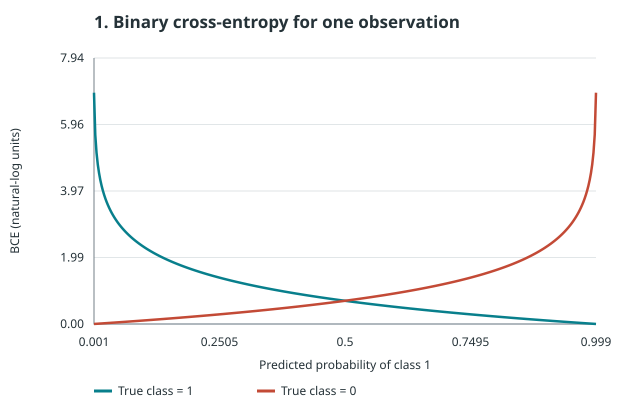

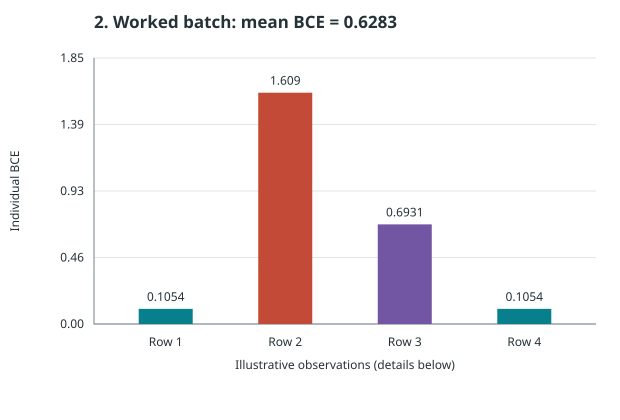

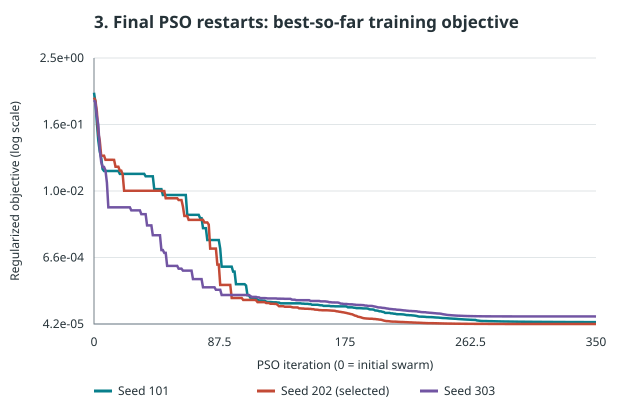

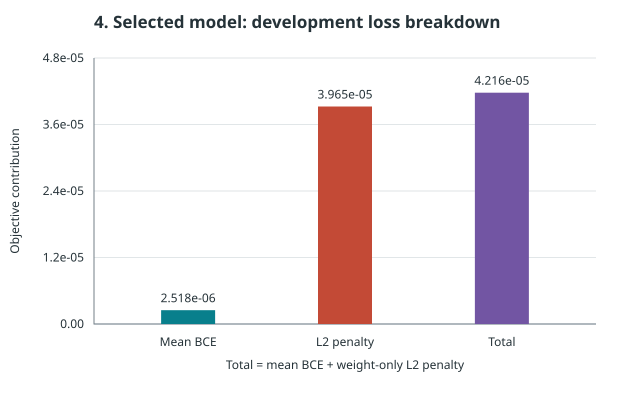

Worked batch (illustrative data, not banknote samples):
Row | True class | P(class 1) | Individual BCE
  1 |          1 |       0.90 | 0.105361
  2 |          0 |       0.80 | 1.609438
  3 |          1 |       0.50 | 0.693147
  4 |          0 |       0.10 | 0.105361
Mean BCE = sum(individual losses) / 4 = 0.628327
Development objective = 2.5177305e-06 BCE + 3.9646345e-05 L2 = 4.2164075e-05
Graph checks passed: worked loss calculation, objective decomposition and monotone PSO histories.


In [9]:
from html import escape


probability_grid = np.linspace(0.001, 0.999, 400)
illustrative_labels = np.array([1, 0, 1, 0])
illustrative_probabilities = np.array([0.9, 0.8, 0.5, 0.1])
illustrative_losses = -(
    illustrative_labels * np.log(illustrative_probabilities)
    + (1 - illustrative_labels) * np.log1p(-illustrative_probabilities)
)
development_logits = final_network.forward(
    scaled_development, FINAL_PARAMETERS, return_logits=True
)[0, :, 0]
development_row_losses = (
    np.logaddexp(0.0, development_logits) - labels_development * development_logits
)
development_bce = float(development_row_losses.mean())
selected_weights = FINAL_PARAMETERS[final_network.weight_indices]
development_penalty = float(BEST_CONFIG['l2'] * np.mean(selected_weights ** 2))
objective_components = np.array([
    development_bce, development_penalty, development_bce + development_penalty
])
np.testing.assert_allclose(illustrative_losses, -np.log([0.9, 0.2, 0.5, 0.9]))
np.testing.assert_allclose(objective_components[-1], final_fit['cost'], rtol=1e-10, atol=1e-12)
for restart_seed, restart_fit in final_runs:
    assert np.isfinite(restart_fit['history']).all()
    assert np.all(restart_fit['history'] > 0)
    assert np.all(np.diff(restart_fit['history']) <= 0)


def loss_chart_svg(title, series, x_label, y_label, *, log_y=False, bar_labels=None):
    """Render a small, dependency-free SVG chart for notebook display."""
    width, height = 620, 420
    left, top, plot_width, plot_height = 94, 58, 502, 266
    palette = ('#087f8c', '#c34a36', '#7255a3')
    all_horizontal = np.concatenate([np.asarray(horizontal) for _, horizontal, _ in series])
    all_vertical = np.concatenate([np.asarray(vertical) for _, _, vertical in series])
    if not np.isfinite(all_horizontal).all() or not np.isfinite(all_vertical).all():
        raise ValueError('Graph data must be finite.')
    if log_y and np.any(all_vertical <= 0):
        raise ValueError('Logarithmic graph values must be positive.')
    horizontal_min, horizontal_max = float(all_horizontal.min()), float(all_horizontal.max())
    if bar_labels is not None:
        horizontal_min -= 0.6
        horizontal_max += 0.6
    transformed_vertical = np.log10(all_vertical) if log_y else all_vertical
    vertical_min = float(transformed_vertical.min()) if log_y else 0.0
    vertical_max = float(transformed_vertical.max())
    vertical_span = max(vertical_max - vertical_min, 1e-12)
    vertical_max += vertical_span * 0.15

    def horizontal_pixel(value):
        return left + (value - horizontal_min) / max(horizontal_max - horizontal_min, 1e-12) * plot_width

    def vertical_pixel(value):
        transformed = np.log10(value) if log_y else value
        return top + plot_height * (1 - (transformed - vertical_min) / (vertical_max - vertical_min))

    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" '
        f'width="100%" style="max-width:760px;background:white" role="img" aria-label="{escape(title)}">',
        '<style>text{font-family:Verdana,sans-serif;font-size:12px;fill:#253238}</style>',
        f'<text x="{left}" y="28" style="font-size:17px;font-weight:bold">{escape(title)}</text>',
    ]
    for tick in np.linspace(vertical_min, vertical_max, 5):
        value = 10 ** tick if log_y else tick
        pixel = vertical_pixel(value)
        parts.append(f'<path d="M {left} {pixel:.2f} h {plot_width}" stroke="#e1e6e8"/>')
        label = f'{value:.1e}' if log_y or (0 < abs(value) < 0.01) else f'{value:.2f}'
        parts.append(f'<text x="{left - 10}" y="{pixel + 4:.2f}" text-anchor="end">{label}</text>')
    horizontal_ticks = np.arange(len(bar_labels)) if bar_labels is not None else np.linspace(horizontal_min, horizontal_max, 5)
    for tick_index, tick in enumerate(horizontal_ticks):
        label = bar_labels[tick_index] if bar_labels is not None else f'{tick:g}'
        parts.append(f'<text x="{horizontal_pixel(tick):.2f}" y="{top + plot_height + 22}" text-anchor="middle">{escape(label)}</text>')
    parts.append(f'<path d="M {left} {top} v {plot_height} h {plot_width}" fill="none" stroke="#73828a"/>')
    for series_index, (name, horizontal, vertical) in enumerate(series):
        colour = palette[series_index % len(palette)]
        if bar_labels is not None:
            for point_index, (horizontal_value, vertical_value) in enumerate(zip(horizontal, vertical)):
                point_colour = palette[point_index % len(palette)]
                pixel = vertical_pixel(vertical_value)
                parts.append(f'<rect x="{horizontal_pixel(horizontal_value) - 27:.2f}" y="{pixel:.2f}" width="54" height="{top + plot_height - pixel:.2f}" fill="{point_colour}"/>')
                parts.append(f'<text x="{horizontal_pixel(horizontal_value):.2f}" y="{pixel - 8:.2f}" text-anchor="middle">{vertical_value:.4g}</text>')
        else:
            coordinates = ' '.join(f'{horizontal_pixel(horizontal_value):.2f},{vertical_pixel(vertical_value):.2f}' for horizontal_value, vertical_value in zip(horizontal, vertical))
            parts.append(f'<polyline points="{coordinates}" fill="none" stroke="{colour}" stroke-width="2.5"/>')
            legend_horizontal = left + series_index * 163
            parts.append(f'<path d="M {legend_horizontal} 391 h 18" stroke="{colour}" stroke-width="3"/>')
            parts.append(f'<text x="{legend_horizontal + 24}" y="395">{escape(name)}</text>')
    parts.append(f'<text x="{left + plot_width / 2}" y="369" text-anchor="middle">{escape(x_label)}</text>')
    parts.append(f'<text transform="translate(19 {top + plot_height / 2}) rotate(-90)" text-anchor="middle">{escape(y_label)}</text>')
    return ''.join(parts) + '</svg>'


loss_graphs = [
    loss_chart_svg(
        '1. Binary cross-entropy for one observation',
        [('True class = 1', probability_grid, -np.log(probability_grid)),
         ('True class = 0', probability_grid, -np.log1p(-probability_grid))],
        'Predicted probability of class 1', 'BCE (natural-log units)',
    ),
    loss_chart_svg(
        f'2. Worked batch: mean BCE = {illustrative_losses.mean():.4f}',
        [('Individual BCE', np.arange(4), illustrative_losses)],
        'Illustrative observations (details below)', 'Individual BCE',
        bar_labels=['Row 1', 'Row 2', 'Row 3', 'Row 4'],
    ),
    loss_chart_svg(
        '3. Final PSO restarts: best-so-far training objective',
        [(f'Seed {restart_seed}' + (' (selected)' if restart_seed == FINAL_SEED else ''),
          np.arange(len(restart_fit['history'])), restart_fit['history'])
         for restart_seed, restart_fit in final_runs],
        'PSO iteration (0 = initial swarm)', 'Regularized objective (log scale)', log_y=True,
    ),
    loss_chart_svg(
        '4. Selected model: development loss breakdown',
        [('Loss components', np.arange(3), objective_components)],
        'Total = mean BCE + weight-only L2 penalty', 'Objective contribution',
        bar_labels=['Mean BCE', 'L2 penalty', 'Total'],
    ),
]
assert len(loss_graphs) == 4
for loss_graph in loss_graphs:
    assert '<polyline' in loss_graph or '<rect' in loss_graph
    display({'image/svg+xml': loss_graph}, raw=True)
print('Worked batch (illustrative data, not banknote samples):')
print('Row | True class | P(class 1) | Individual BCE')
for row_number, (label, probability, loss_value) in enumerate(
    zip(illustrative_labels, illustrative_probabilities, illustrative_losses), 1
):
    print(f'{row_number:>3} | {label:>10} | {probability:>10.2f} | {loss_value:.6f}')
print(f'Mean BCE = sum(individual losses) / 4 = {illustrative_losses.mean():.6f}')
print(f'Development objective = {development_bce:.8g} BCE + '
      f'{development_penalty:.8g} L2 = {objective_components[-1]:.8g}')
print('Graph checks passed: worked loss calculation, objective decomposition and monotone PSO histories.')